# Drifting effects in bike-share demand

A bike-share operator records the number of pickups at every station, every day. A Poisson regression on station characteristics explains much of the variation across stations on any one day: stations near a transit hub serve commuters, and stations near a park serve leisure riders. The regression's coefficients do not stay fixed. The city-wide level of demand moves with the weather, the commuting effect shifts slowly as work patterns change, and the park effect rises and falls with the seasons.

Fitting the regression separately on each day discards what yesterday's coefficients say about today's, and a day on which some stations are offline is fit on fewer observations. Treating the coefficients as the states of a random walk pools the days. Each day's pickups update a Gaussian belief about the coefficients, and the random walk carries that belief to the next day:

$$
y_{it} \sim \operatorname{Poisson}\left(\exp(x_i^\top \beta_t)\right), \qquad
\beta_t = \beta_{t-1} + \eta_t, \qquad
\eta_t \sim N\left(0, \operatorname{diag}(\sigma^2)\right).
$$

The speed of each walk, $\sigma$, is a parameter to estimate. A large $\sigma$ lets a coefficient follow each day's data closely, and a small one smooths it across many days.

`pymc_extras.statespace.nonlinear` builds the filter for this model from two pieces written separately: a PyMC model of a single day's cross-section, and a `PyMCStateSpace` for how its parameters evolve. Each day's update is a Laplace approximation around the mode of the coefficients' posterior, so the Poisson likelihood is used as it is, with no linearization of the data.

In [1]:
import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
import xarray as xr

from pytensor_ml.optim import zoom_line_search
from scipy.stats import norm

import pymc_extras as pmx

from pymc_extras.statespace import structural as st
from pymc_extras.statespace.nonlinear import FusedStateSpace, observed_state_names, run_filter

ESTIMATE_COLOR = "#2a78d6"
FILTER_COLOR = "#eb6834"
TRUTH_COLOR = "#2b2b2a"

seed = sum(map(ord, "Statespace from Nonlinear Model"))
rng = np.random.default_rng(seed=seed)

## Simulated stations

The data come from the model itself, so the estimates can be checked against the truth. There are 60 stations, each with a standardized distance to the nearest transit hub and to the nearest park, observed for 180 days. The three coefficients -- the city-wide demand level and the two proximity effects -- each follow a random walk at its own speed. On any day, a station is offline with probability 5%, and its pickups for that day are missing.

In [3]:
effects = ["level", "transit", "park"]
n_stations, n_days = 60, 180

transit_proximity = rng.normal(size=n_stations)
park_proximity = rng.normal(size=n_stations)
design = np.column_stack([np.ones(n_stations), transit_proximity, park_proximity])

true_initial = np.array([1.5, 0.5, 0.2])
true_sigma = np.array([0.08, 0.02, 0.04])
true_paths = true_initial + np.cumsum(true_sigma * rng.normal(size=(n_days, 3)), axis=0)

rates = np.exp(true_paths @ design.T)
pickups = rng.poisson(rates)
online = rng.uniform(size=(n_days, n_stations)) > 0.05

design_by_day = [design[online[day]] for day in range(n_days)]
pickups_by_day = [pickups[day, online[day]] for day in range(n_days)]

print(f"Mean pickups per station-day: {pickups[online].mean():.1f}")
print(f"Station-days offline: {(~online).sum()} of {online.size}")

Mean pickups per station-day: 1.9
Station-days offline: 544 of 10800


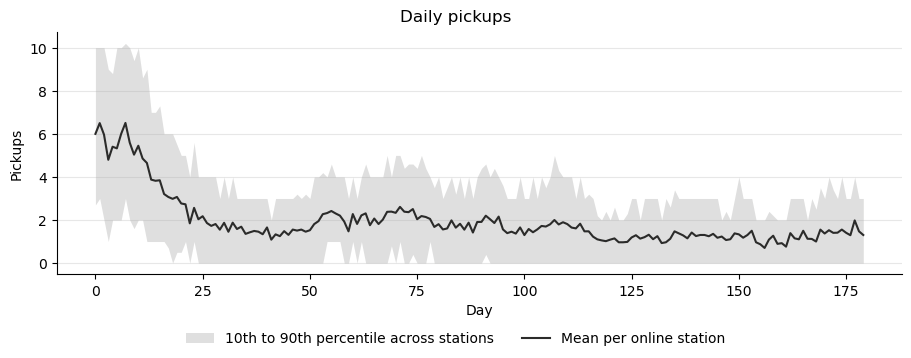

In [4]:
observed_pickups = np.where(online, pickups, np.nan)
days = np.arange(n_days)

fig, axis = plt.subplots(figsize=(9, 3.5), layout="constrained")
axis.fill_between(
    days,
    np.nanpercentile(observed_pickups, 10, axis=1),
    np.nanpercentile(observed_pickups, 90, axis=1),
    color=TRUTH_COLOR,
    alpha=0.15,
    linewidth=0,
    label="10th to 90th percentile across stations",
)
axis.plot(
    days,
    np.nanmean(observed_pickups, axis=1),
    color=TRUTH_COLOR,
    linewidth=1.5,
    label="Mean per online station",
)
axis.set_xlabel("Day")
axis.set_ylabel("Pickups")
axis.spines[["top", "right"]].set_visible(False)
axis.grid(axis="y", alpha=0.3)
fig.suptitle("Daily pickups")
fig.legend(*axis.get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False);

## One day's model

The model of a single day is an ordinary PyMC Poisson regression. Its data are placeholders: the filter swaps in each day's design matrix and pickups, so the shapes given here do not constrain the number of stations online on any day. The prior on `beta` plays no role in the filter, because the dynamics supply the prior on each day's coefficients.

In [5]:
with pm.Model(coords={"effect": effects}) as station_model:
    X = pm.Data("X", design)
    beta = pm.Normal("beta", dims="effect")
    pm.Poisson("pickups", mu=pm.math.exp(X @ beta), observed=pickups[0])

## Dynamics

`observed_state_names` lists the elements of `beta` by name, and a structural `LevelTrend` with one innovation per element makes each of them a random walk. `FusedStateSpace` joins the two: the elements of `beta` become the states that the statespace observes, with their default transforms applied.

In [6]:
names = observed_state_names(model=station_model, rv_names=["beta"])
random_walk = st.LevelTrend(order=1, innovations_order=1, observed_state_names=names["beta"])
ss_mod = random_walk.build()

                                          Model Requirements                                          
                                                                                                      
  Variable              Shape    Constraints                                              Dimensions  
 ──────────────────────────────────────────────────────────────────────────────────────────────────── 
  initial_level_trend   (3, 1)                            ('endog_level_trend', 'state_level_trend')  
  sigma_level_trend     (3, 1)   Positive                 ('endog_level_trend', 'shock_level_trend')  
  P0                    (3, 3)   Positive semi-definite                       ('state', 'state_aux')  
                                                                                                      
       These parameters should be assigned priors inside a PyMC model block before calling the        
                                    build_statespace_graph method.                                    

In [7]:
fused = FusedStateSpace(
    model=station_model,
    statespace=ss_mod,
    rv_names=["beta"],
    frozen={},
    curvature="fisher",
    line_search=zoom_line_search(),
    tolerance=1e-8,
    max_iterations=20,
    prior_weight=0.0,
)

## Filtering at known drift scales

As with any statespace model in `pymc_extras`, the statespace's parameters get priors in a PyMC model, under the names and dims the fused model reports, and `build_statespace_graph` registers the observations.

With the drift scales fixed at their true values, the filter passes over the days once. On each day it finds the mode of the coefficients' posterior given that day's pickups and the belief carried from the day before, takes the Gaussian around that mode as the filtered belief, and predicts the next day with the random walk. A backward pass then smooths each day's belief with the days after it. `sample_conditional_posterior` runs the filter and smoother for every draw of the parameters and draws paths from the result; here the parameters are a single draw at their true values. The filter starts from a vague belief, centered at zero with unit variance on each coefficient.

In [8]:
with pm.Model(coords=fused.coords) as drift_model:
    pm.Normal("initial_level_trend", sigma=2.0, dims=fused.param_dims["initial_level_trend"])
    pm.HalfNormal("sigma_level_trend", sigma=0.1, dims=fused.param_dims["sigma_level_trend"])
    pm.Deterministic("P0", pt.eye(3), dims=fused.param_dims["P0"])
    fused.build_statespace_graph(
        data={"X": design_by_day, "pickups": pickups_by_day}, dates=np.arange(n_days)
    )

In [9]:
known = run_filter(
    fused=fused,
    statespace_parameters={
        "initial_level_trend": np.zeros((3, 1)),
        "sigma_level_trend": true_sigma[:, None],
        "P0": np.eye(3),
    },
    statespace_data={},
    data={"X": design_by_day, "pickups": pickups_by_day},
    dates=np.arange(n_days),
)["posterior_predictive"]

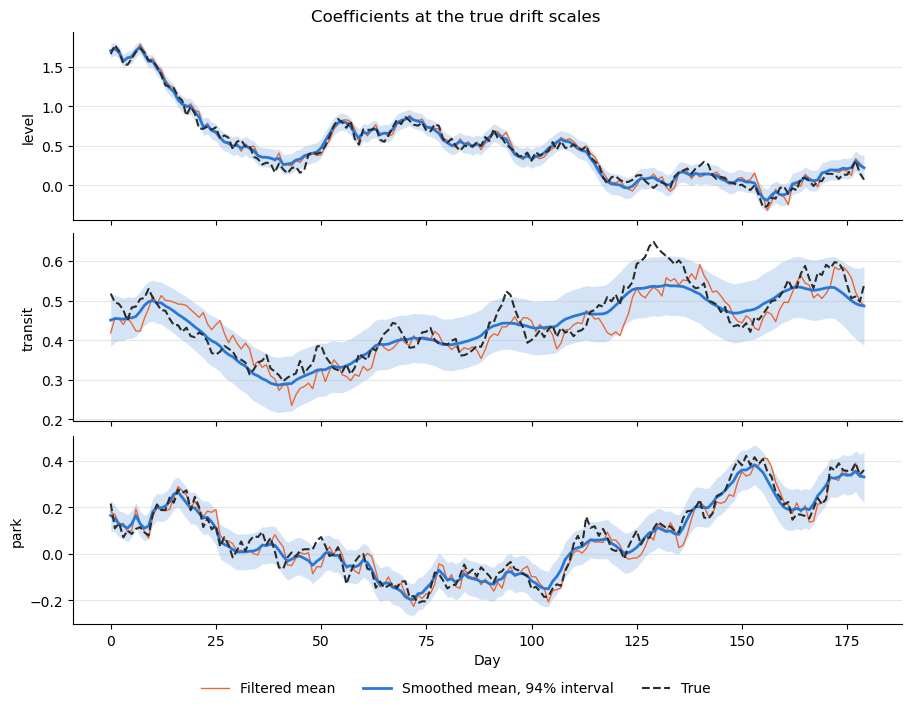

In [10]:
def plot_moments(*, moments, truth, labels, x, title, transforms, show_filtered):
    """Plot each state's smoothed mean and 94% interval from the filter's closed-form moments."""
    z_score = norm.ppf(0.97)

    def mean_and_sd(kind):
        mean = moments[f"{kind}_states"].isel(chain=0, draw=0).values
        sd = np.sqrt(
            np.diagonal(
                moments[f"{kind}_covariances"].isel(chain=0, draw=0).values, axis1=-2, axis2=-1
            )
        )
        return mean, sd

    smoothed_mean, smoothed_sd = mean_and_sd("smoothed")
    filtered_mean, _ = mean_and_sd("filtered")

    fig, axes = plt.subplots(len(labels), 1, figsize=(9, 7), sharex=True, layout="constrained")
    for index, (axis, label, transform) in enumerate(zip(axes, labels, transforms)):
        axis.fill_between(
            x,
            transform(smoothed_mean[:, index] - z_score * smoothed_sd[:, index]),
            transform(smoothed_mean[:, index] + z_score * smoothed_sd[:, index]),
            color=ESTIMATE_COLOR,
            alpha=0.2,
            linewidth=0,
        )
        if show_filtered:
            axis.plot(
                x,
                transform(filtered_mean[:, index]),
                color=FILTER_COLOR,
                linewidth=1,
                label="Filtered mean",
            )
        axis.plot(
            x,
            transform(smoothed_mean[:, index]),
            color=ESTIMATE_COLOR,
            linewidth=2,
            label="Smoothed mean, 94% interval",
        )
        axis.plot(
            x, truth[:, index], color=TRUTH_COLOR, linewidth=1.5, linestyle="--", label="True"
        )
        axis.set_ylabel(label)
        axis.spines[["top", "right"]].set_visible(False)
        axis.grid(axis="y", alpha=0.3)
    axes[-1].set_xlabel("Week" if np.issubdtype(np.asarray(x).dtype, np.datetime64) else "Day")
    fig.suptitle(title)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, legend_labels, loc="outside lower center", ncols=len(legend_labels), frameon=False
    )
    return fig


def plot_paths(*, paths, truth, labels, x, title, filtered=None):
    """Plot each column of ``paths`` as a median with a 94% HDI over the draws, against the true paths."""
    hdi = az.hdi(paths, prob=0.94)
    median = paths.median(("chain", "draw")).values

    fig, axes = plt.subplots(len(labels), 1, figsize=(9, 7), sharex=True, layout="constrained")
    for index, (axis, label) in enumerate(zip(axes, labels)):
        axis.fill_between(
            x,
            hdi.sel(ci_bound="lower").values[:, index],
            hdi.sel(ci_bound="upper").values[:, index],
            color=ESTIMATE_COLOR,
            alpha=0.2,
            linewidth=0,
        )
        if filtered is not None:
            axis.plot(
                x,
                filtered.median(("chain", "draw")).values[:, index],
                color=FILTER_COLOR,
                linewidth=1,
                label="Filtered median",
            )
        axis.plot(
            x, median[:, index], color=ESTIMATE_COLOR, linewidth=2, label="Smoothed median, 94% HDI"
        )
        axis.plot(
            x, truth[:, index], color=TRUTH_COLOR, linewidth=1.5, linestyle="--", label="True"
        )
        axis.set_ylabel(label)
        axis.spines[["top", "right"]].set_visible(False)
        axis.grid(axis="y", alpha=0.3)
    axes[-1].set_xlabel("Week" if np.issubdtype(np.asarray(x).dtype, np.datetime64) else "Day")
    fig.suptitle(title)
    handles, legend_labels = axes[0].get_legend_handles_labels()
    fig.legend(
        handles, legend_labels, loc="outside lower center", ncols=len(legend_labels), frameon=False
    )
    return fig


plot_moments(
    moments=known,
    truth=true_paths,
    labels=effects,
    x=np.arange(n_days),
    title="Coefficients at the true drift scales",
    transforms=[np.asarray] * len(effects),
    show_filtered=True,
);

## Estimating the drift scales

The drift scales are not known in practice. The pickups are an observed variable of the model above, and its log-probability is the filter's: the sum over days of each day's Laplace approximation to the probability of that day's pickups. Its draws simulate the random walk and then each station's pickups, so prior and posterior predictive sampling work as they do for any PyMC model. The gradient of the log-probability with respect to the drift scales passes through every day's mode, so any of PyMC's gradient-based fitting methods applies. Here Pathfinder fits the scales and the starting coefficients together.

In [11]:
with drift_model:
    estimate = pmx.fit_pathfinder(
        vectorize_logp=False, vectorize_postprocessing=False, random_seed=rng
    )

Output()

Output()

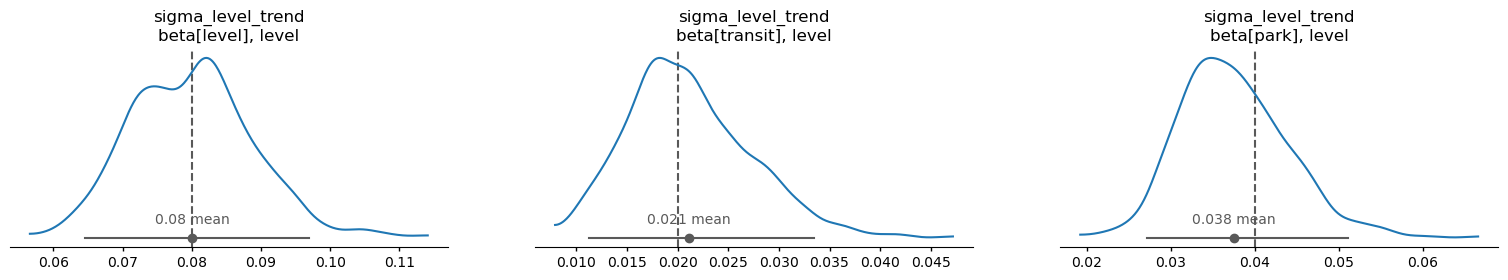

In [12]:
sigma_estimate = estimate.posterior["sigma_level_trend"].isel(chain=0, draw=0, drop=True)
true_sigma_values = sigma_estimate.copy(data=true_sigma[:, None]).to_dataset()
plot = az.plot_dist(estimate, var_names=["sigma_level_trend"])
az.add_lines(plot, values=true_sigma_values);

## Coefficients given the estimated drift scales

`sample_conditional_posterior` runs the filter and smoother once for each posterior draw of the parameters and draws a path of coefficients from the result, so the plotted bands carry the uncertainty in the drift scales as well as in the coefficients.

Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

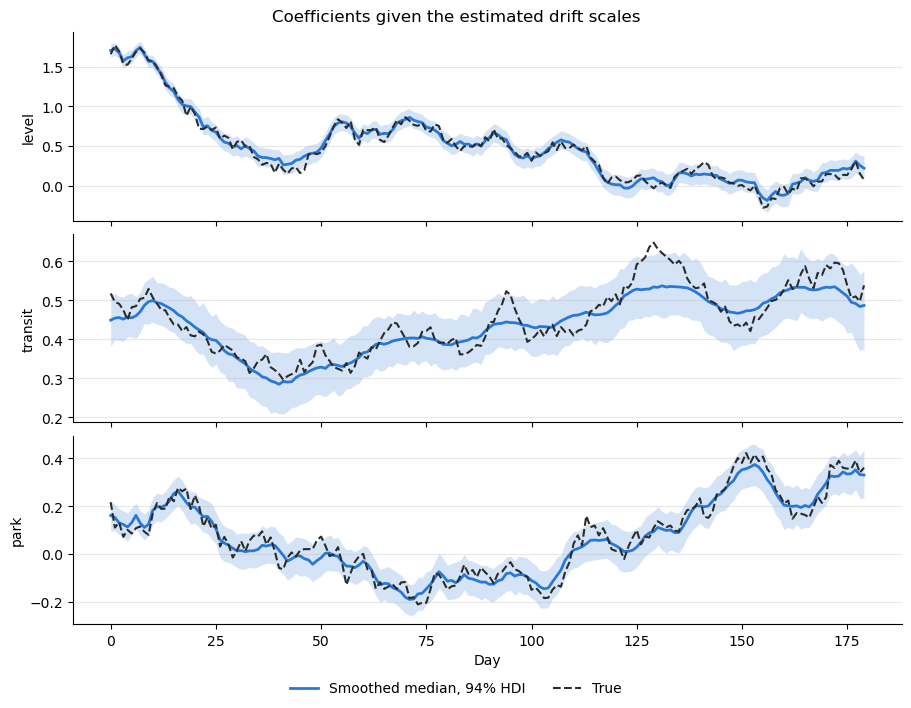

In [13]:
conditional = fused.sample_conditional_posterior(estimate, random_seed=rng)
smoothed = conditional["smoothed_posterior_observed"]

plot_paths(
    paths=smoothed,
    truth=true_paths,
    labels=effects,
    x=np.arange(n_days),
    title="Coefficients given the estimated drift scales",
);

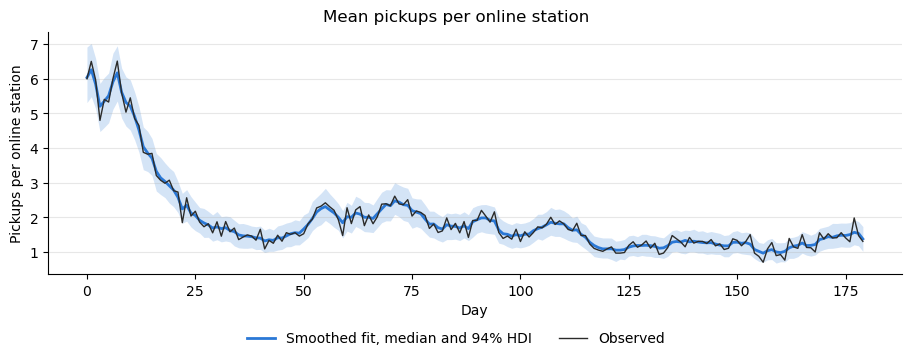

In [14]:
def plot_fitted_observations(*, draws, observed, x, ylabel, title):
    """Plot the mean over each date's observations, from every draw, against the observed mean."""
    date_means = draws.mean(dim=draws.dims[3:], skipna=True)
    hdi = az.hdi(date_means, prob=0.94)

    fig, axis = plt.subplots(figsize=(9, 3.5), layout="constrained")
    axis.fill_between(
        x,
        hdi.sel(ci_bound="lower"),
        hdi.sel(ci_bound="upper"),
        color=ESTIMATE_COLOR,
        alpha=0.2,
        linewidth=0,
    )
    axis.plot(
        x,
        date_means.median(("chain", "draw")),
        color=ESTIMATE_COLOR,
        linewidth=2,
        label="Smoothed fit, median and 94% HDI",
    )
    axis.plot(x, observed, color=TRUTH_COLOR, linewidth=1, label="Observed")
    axis.set_xlabel("Week" if np.issubdtype(np.asarray(x).dtype, np.datetime64) else "Day")
    axis.set_ylabel(ylabel)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", alpha=0.3)
    fig.suptitle(title)
    fig.legend(
        *axis.get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False
    )
    return fig


fitted_pickups = fused.sample_conditional_observations(
    idata=estimate, conditional=conditional, kind="smoothed", random_seed=rng
)
plot_fitted_observations(
    draws=fitted_pickups["pickups"],
    observed=np.nanmean(observed_pickups, axis=1),
    x=days,
    ylabel="Pickups per online station",
    title="Mean pickups per online station",
);

# A time-varying marketing mix model

A marketing mix model (MMM) explains sales from what was spent on each advertising channel. The one below follows the default model in `pymc-marketing`. In one week, sales are an intercept plus each channel's contribution:

$$
y \sim N\left(\alpha + \sum_c \beta_c \, s\left(\operatorname{adstock}(x_c; \theta_c); \lambda_c\right), \; \sigma^2\right).
$$

The adstock is geometric over the last $L$ weeks of spend, with weights normalized to sum to one, so spend keeps working after the week it is made:

$$
\operatorname{adstock}(x; \theta) = \frac{\sum_{l=0}^{L-1} \theta^l \, x_{t-l}}{\sum_{l=0}^{L-1} \theta^l}.
$$

The logistic saturation $s(u; \lambda) = (1 - e^{-\lambda u}) / (1 + e^{-\lambda u})$ makes each additional dollar earn less than the one before it, and $\beta_c$ is the contribution a channel approaches at full saturation. Sales are scaled by their maximum, as `pymc-marketing` does.

A fit over a long history needs extra terms for everything that moves the baseline: a trend, Fourier terms for the season, and a dummy for each special event. The fused filter instead makes the intercept a state. Every week's sales update it through the one-week model's own likelihood, so the trend and the season are absorbed by the moving intercept without being modeled. The first model below gives the intercept a random walk; the second builds it from a smooth level and a yearly season.

## The `pymc-marketing` example data

The data are generated exactly as in the `pymc-marketing` MMM example (`mmm_example.ipynb`), with its seed: 179 weeks of one market, two channels, a trend, a yearly season and two one-week events. Channel `x1` spends every week, with occasional bursts, and `x2` runs occasional campaigns. The example's `geometric_adstock` and `logistic_saturation` are reproduced in NumPy, with its decays, saturation rates and channel effects $\beta = (3, 2)$.

The channel effects are constant. The baseline -- the intercept of 2, the trend, the season and the events -- is what moves.

In [15]:
channels = ["x1", "x2"]
n_lags = 8
mmm_rng = np.random.default_rng(seed=sum(map(ord, "mmm")))

date_week = pd.date_range(start="2018-04-01", end="2021-09-01", freq="W-MON")
n_weeks = len(date_week)
weeks = np.arange(n_weeks)

x1 = mmm_rng.uniform(low=0.0, high=1.0, size=n_weeks)
x1 = np.where(x1 > 0.9, x1, x1 / 2)
x2 = mmm_rng.uniform(low=0.0, high=1.0, size=n_weeks)
x2 = np.where(x2 > 0.8, x2, 0)
spend = np.column_stack([x1, x2])

# Each week's last n_lags weeks of spend, most recent first, with zeros before the first week.
padded = np.concatenate([np.zeros((n_lags - 1, len(channels))), spend])
spend_lags = np.stack(
    [padded[n_lags - 1 - lag : n_lags - 1 - lag + n_weeks] for lag in range(n_lags)], axis=-1
)

adstock_alpha = np.array([0.4, 0.2])
saturation_lam = np.array([4.0, 3.0])
lag_weights = adstock_alpha[:, None] ** np.arange(n_lags)
adstocked = (spend_lags * lag_weights).sum(axis=-1) / lag_weights.sum(axis=-1)
saturated = (1 - np.exp(-saturation_lam * adstocked)) / (1 + np.exp(-saturation_lam * adstocked))

dayofyear = date_week.day_of_year.to_numpy()
trend = (np.linspace(start=0.0, stop=50, num=n_weeks) + 10) ** (1 / 4) - 1
seasonality = 0.5 * (
    -np.sin(2 * 2 * np.pi * dayofyear / 365.5) + np.cos(1 * 2 * np.pi * dayofyear / 365.5)
)
event_1 = (date_week == "2019-05-13").astype(float)
event_2 = (date_week == "2020-09-14").astype(float)
noise_sigma = 0.25
epsilon = mmm_rng.normal(loc=0.0, scale=noise_sigma, size=n_weeks)

channel_betas = np.array([3.0, 2.0])
baseline = 2.0 + trend + seasonality + 1.5 * event_1 + 2.5 * event_2
sales = baseline + saturated @ channel_betas + epsilon

sales_scale = sales.max()
sales_scaled = sales / sales_scale
true_paths_scaled = np.column_stack([baseline, np.tile(channel_betas, (n_weeks, 1))]) / sales_scale
print(f"Weeks: {n_weeks}, sales scale: {sales_scale:.3f}")

Weeks: 179, sales scale: 8.312


## One week's model

The one-week model is the `pymc-marketing` MMM for a single week, with its default priors. Its data are the last eight weeks of spend per channel and that week's scaled sales, and it computes the adstock and saturation itself. A week has one sales figure, so both data arrays carry a leading axis of length one. The adstock decays, the saturation rates and the noise scale come from a static fit over the whole history; here they are held at their true values through `frozen`. The contribution ceilings `saturation_beta` have `HalfNormal` priors, so the filter tracks their logs, the scale of their default transform.

In [16]:
with pm.Model(coords={"channel": channels}) as week_model:
    lags = pm.Data("spend_lags", spend_lags[:1])

    intercept = pm.Normal("intercept", mu=0.0, sigma=2.0)
    alpha = pm.Beta("adstock_alpha", alpha=1.0, beta=3.0, dims="channel")
    lam = pm.Gamma("saturation_lam", alpha=3.0, beta=1.0, dims="channel")
    beta = pm.HalfNormal("saturation_beta", sigma=2.0, dims="channel")
    sigma = pm.HalfNormal("sigma", sigma=2.0)

    lag_weights = alpha[:, None] ** pt.arange(n_lags)
    adstock = (lags * lag_weights).sum(axis=-1) / lag_weights.sum(axis=-1)
    saturation = (1 - pt.exp(-lam * adstock)) / (1 + pt.exp(-lam * adstock))
    mu = intercept + (beta * saturation).sum(axis=-1)
    pm.Normal("sales", mu=mu, sigma=sigma, observed=sales_scaled[:1])

## A moving baseline

The intercept gets a random walk, and the channel effects `saturation_beta` stay constant: their states are a `LevelTrend` without innovations. With one sales figure per week, the data cannot tell a moving intercept from moving channel effects, so letting both drift lets the channel effects absorb the season. `rv_names` lists the variables that become states, and `frozen` holds the adstock decays, saturation rates and noise scale at fixed values. Below, the statespace's parameters get priors in a PyMC model, and the paths are first drawn at a hand-set drift scale; the next section estimates it.

`prior_weight` adds the one-week model's priors to every week's likelihood. The channel effects do not change from week to week, so a weight of 1 would apply their prior once per week and pull them toward zero with the force of 179 priors. A weight of `1 / n_weeks` applies it once in total.

In [17]:
state_variables = ["intercept", "saturation_beta"]
mmm_names = observed_state_names(model=week_model, rv_names=state_variables)
mmm_walk = (
    st.LevelTrend(
        name="baseline", order=1, innovations_order=1, observed_state_names=mmm_names["intercept"]
    )
    + st.LevelTrend(
        name="channel",
        order=1,
        innovations_order=0,
        observed_state_names=mmm_names["saturation_beta"],
    )
).build()

                                    Model Requirements                                     
                                                                                           
  Variable           Shape    Constraints                                      Dimensions  
 ───────────────────────────────────────────────────────────────────────────────────────── 
  initial_baseline   (1,)                                             ('state_baseline',)  
  sigma_baseline     (1,)     Positive                                ('shock_baseline',)  
  initial_channel    (2, 1)                            ('endog_channel', 'state_channel')  
  P0                 (3, 3)   Positive semi-definite               ('state', 'state_aux')  
                                                                                           
  These parameters should be assigned priors inside a PyMC model block before calling the  
                              build_statespace_graph method.                               

In [18]:
mmm_fused = FusedStateSpace(
    model=week_model,
    statespace=mmm_walk,
    rv_names=state_variables,
    frozen={
        "adstock_alpha": adstock_alpha,
        "saturation_lam": saturation_lam,
        "sigma": noise_sigma / sales_scale,
    },
    curvature="fisher",
    line_search=zoom_line_search(),
    tolerance=1e-8,
    max_iterations=50,
    prior_weight=1 / n_weeks,
)
print(mmm_fused.observed_states)

('intercept', 'saturation_beta[x1]', 'saturation_beta[x2]')


In [19]:
with pm.Model(coords=mmm_fused.coords) as mmm_drift_model:
    pm.Normal("initial_baseline", sigma=2.0, dims=mmm_fused.param_dims["initial_baseline"])
    pm.HalfNormal("sigma_baseline", sigma=0.1, dims=mmm_fused.param_dims["sigma_baseline"])
    pm.Normal("initial_channel", sigma=2.0, dims=mmm_fused.param_dims["initial_channel"])
    pm.Deterministic("P0", pt.eye(3), dims=mmm_fused.param_dims["P0"])
    mmm_fused.build_statespace_graph(
        data={"spend_lags": list(spend_lags[:, None]), "sales": list(sales_scaled[:, None])},
        dates=weeks,
    )

mmm_known = run_filter(
    fused=mmm_fused,
    statespace_parameters={
        "initial_baseline": np.array([0.3]),
        "sigma_baseline": np.array([0.02]),
        "initial_channel": np.log([[0.3], [0.3]]),
        "P0": np.eye(3),
    },
    statespace_data={},
    data={"spend_lags": list(spend_lags[:, None]), "sales": list(sales_scaled[:, None])},
    dates=weeks,
)["posterior_predictive"]

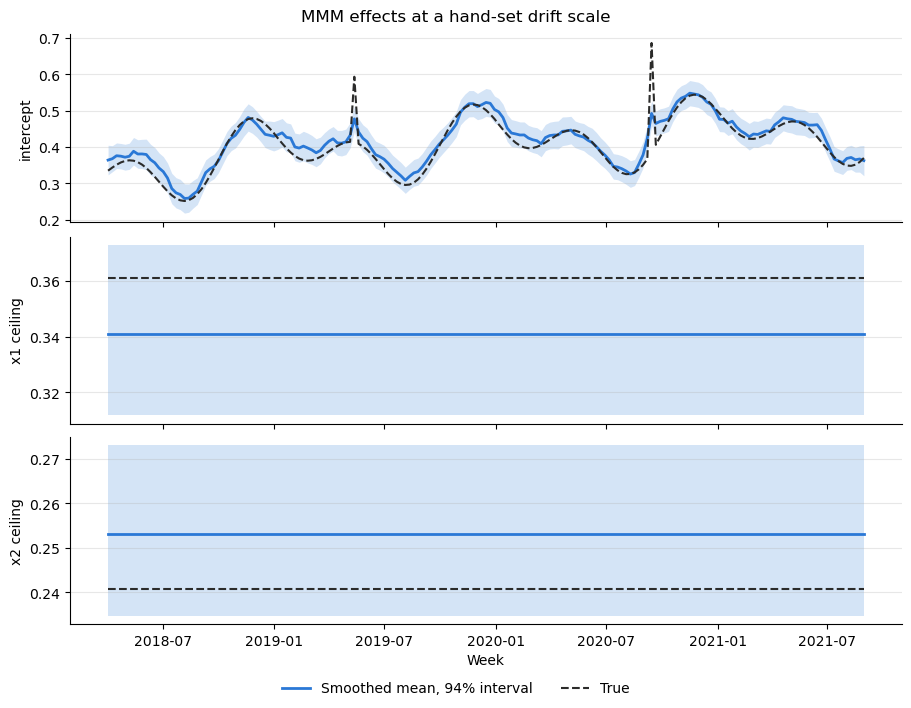

In [20]:
def effect_scale(paths):
    """Return intercept and log-ceiling paths with the ceilings on their own scale."""
    observed_dim = paths.dims[-1]
    return xr.concat(
        [paths.isel({observed_dim: [0]}), np.exp(paths.isel({observed_dim: [1, 2]}))],
        dim=observed_dim,
    )


mmm_labels = ["intercept", *(f"{channel} ceiling" for channel in channels)]
plot_moments(
    moments=mmm_known,
    truth=true_paths_scaled,
    labels=mmm_labels,
    x=date_week,
    title="MMM effects at a hand-set drift scale",
    transforms=[np.asarray, np.exp, np.exp],
    show_filtered=False,
);

## Estimating the baseline's drift scale

As in the bike-share model, Pathfinder fits the intercept's drift scale and the starting values. The channel effects are constant states, so their starting values are their estimates. The true baseline is not a random walk, so there is no true drift scale to compare against. The check is on the paths the fitted scale produces.

In [21]:
with mmm_drift_model:
    mmm_estimate = pmx.fit_pathfinder(
        vectorize_logp=False, vectorize_postprocessing=False, random_seed=rng
    )

/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(
/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(
/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(


Output()

Output()

In [22]:
az.summary(mmm_estimate, var_names=["sigma_baseline", "initial_channel"], kind="stats")

,mean,sd,eti94_lb,eti94_ub
sigma_baseline[level],0.033,0.0038,0.026,0.04
"initial_channel[saturation_beta[x1], level]",-1.2,0.65,-2.6,-0.17
"initial_channel[saturation_beta[x2], level]",-1.2,0.8,-2.8,0.23


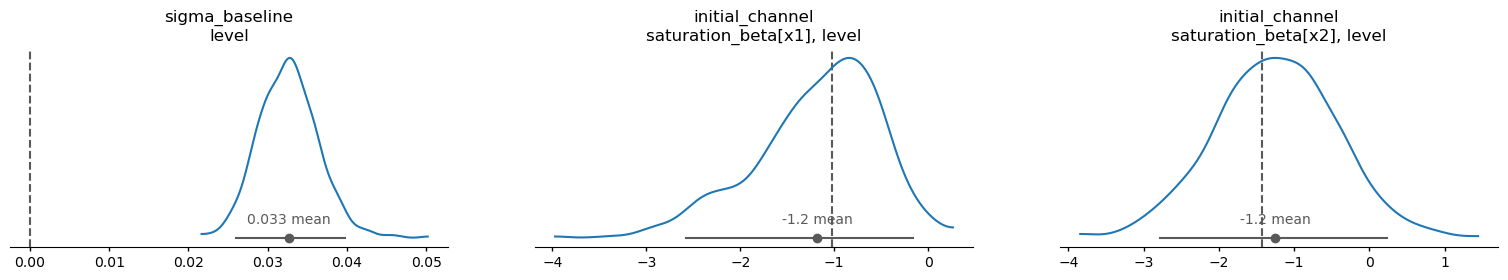

In [23]:
mmm_point = {
    name: mmm_estimate.posterior[name].isel(chain=0, draw=0, drop=True)
    for name in ["sigma_baseline", "initial_channel"]
}
true_mmm_values = xr.Dataset(
    {
        "sigma_baseline": mmm_point["sigma_baseline"].copy(data=[0.0]),
        "initial_channel": mmm_point["initial_channel"].copy(
            data=np.log(channel_betas / sales_scale)[:, None]
        ),
    }
)
plot = az.plot_dist(mmm_estimate, var_names=["sigma_baseline", "initial_channel"])
az.add_lines(plot, values=true_mmm_values);

Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

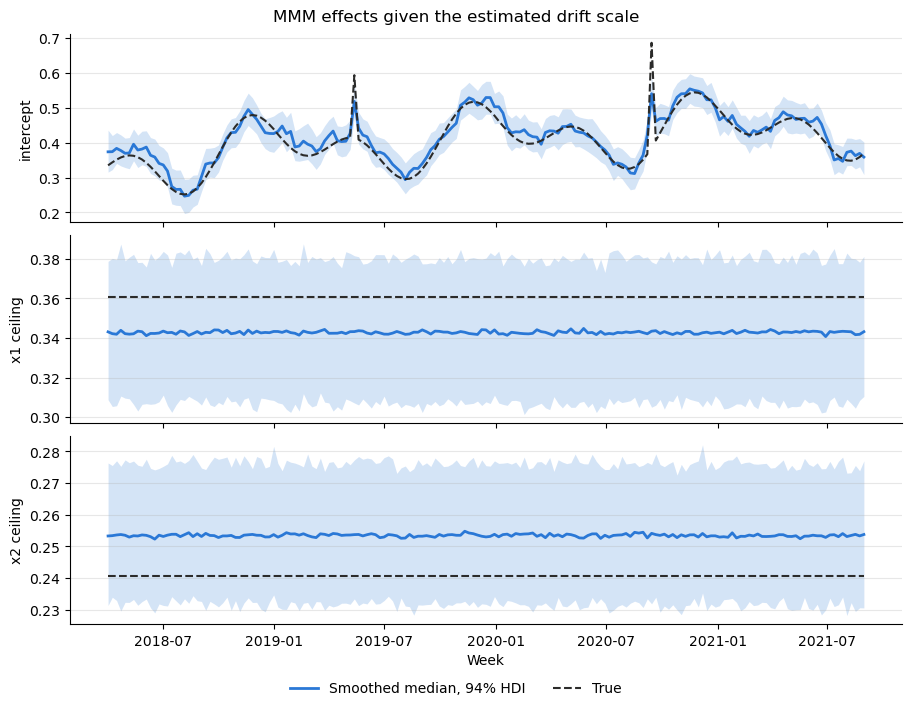

In [24]:
mmm_conditional = mmm_fused.sample_conditional_posterior(mmm_estimate, random_seed=rng)

plot_paths(
    paths=effect_scale(mmm_conditional["smoothed_posterior_observed"]),
    truth=true_paths_scaled,
    labels=mmm_labels,
    x=date_week,
    title="MMM effects given the estimated drift scale",
);

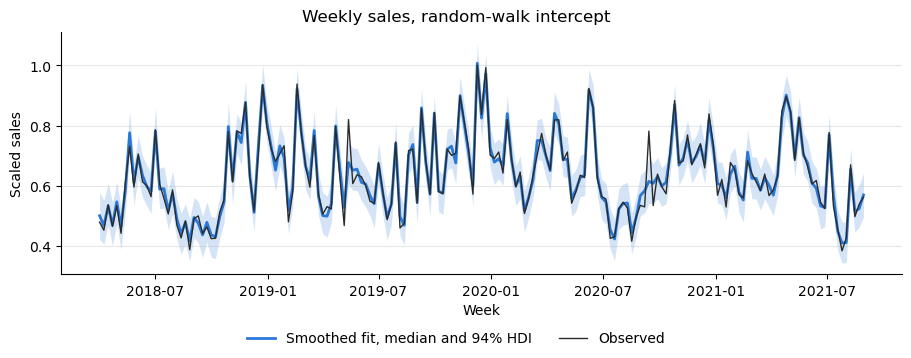

In [25]:
fitted_sales = mmm_fused.sample_conditional_observations(
    idata=mmm_estimate, conditional=mmm_conditional, kind="smoothed", random_seed=rng
)
plot_fitted_observations(
    draws=fitted_sales["sales"],
    observed=sales_scaled,
    x=date_week,
    ylabel="Scaled sales",
    title="Weekly sales, random-walk intercept",
);

## Richer dynamics for the baseline

The random walk follows the baseline but reacts to every week's noise. Structural components replace it without touching the one-week model. Here the intercept is a smooth level plus a yearly season. The level is a `LevelTrend` with `innovations_order=[0, 1]`: only its slope receives shocks, so the level bends gradually instead of jumping week to week. The season is a `FrequencySeasonality` with two harmonics of a 365.5-day year and no innovations. The channel effects stay constant. The intercept is the sum of the level and the season, so the plot shows the observed states, the intercept and the two log ceilings, instead of the individual states.

In [26]:
rich_walk = (
    st.LevelTrend(
        name="baseline",
        order=2,
        innovations_order=[0, 1],
        observed_state_names=mmm_names["intercept"],
    )
    + st.FrequencySeasonality(
        name="season",
        season_length=365.5 / 7,
        n=2,
        innovations=False,
        observed_state_names=mmm_names["intercept"],
    )
    + st.LevelTrend(
        name="channel",
        order=1,
        innovations_order=0,
        observed_state_names=mmm_names["saturation_beta"],
    )
).build()

rich_fused = FusedStateSpace(
    model=week_model,
    statespace=rich_walk,
    rv_names=state_variables,
    frozen={
        "adstock_alpha": adstock_alpha,
        "saturation_lam": saturation_lam,
        "sigma": noise_sigma / sales_scale,
    },
    curvature="fisher",
    line_search=zoom_line_search(),
    tolerance=1e-8,
    max_iterations=50,
    prior_weight=1 / n_weeks,
)

                                    Model Requirements                                     
                                                                                           
  Variable           Shape    Constraints                                      Dimensions  
 ───────────────────────────────────────────────────────────────────────────────────────── 
  initial_baseline   (2,)                                             ('state_baseline',)  
  sigma_baseline     (1,)     Positive                                ('shock_baseline',)  
  params_season      (4,)                                               ('state_season',)  
  initial_channel    (2, 1)                            ('endog_channel', 'state_channel')  
  P0                 (8, 8)   Positive semi-definite               ('state', 'state_aux')  
                                                                                           
  These parameters should be assigned priors inside a PyMC model block before calling the  
                              build_statespace_graph method.                               

In [27]:
# The slope's starting value gets a tighter prior variance than the other states.
rich_P0 = np.diag([1.0, 0.01, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0])

with pm.Model(coords=rich_fused.coords) as rich_model:
    pm.Normal("initial_baseline", sigma=2.0, dims=rich_fused.param_dims["initial_baseline"])
    pm.HalfNormal("sigma_baseline", sigma=0.1, dims=rich_fused.param_dims["sigma_baseline"])
    pm.Normal("params_season", sigma=1.0, dims=rich_fused.param_dims["params_season"])
    pm.Normal("initial_channel", sigma=2.0, dims=rich_fused.param_dims["initial_channel"])
    pm.Deterministic("P0", pt.as_tensor(rich_P0), dims=rich_fused.param_dims["P0"])
    rich_fused.build_statespace_graph(
        data={"spend_lags": list(spend_lags[:, None]), "sales": list(sales_scaled[:, None])},
        dates=weeks,
    )

    rich_estimate = pmx.fit_pathfinder(
        vectorize_logp=False, vectorize_postprocessing=False, random_seed=rng
    )

/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(
/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(
/Users/jesse.grabowski/miniforge3/envs/pymc-extras/lib/python3.14/site-packages/pytensor/tensor/einsum.py:687: UserWarning: The same einsum subscript is used for a broadcastable and non-broadcastable dimension. This can result in a suboptimal contraction path.
  warnings.warn(


Output()

Output()

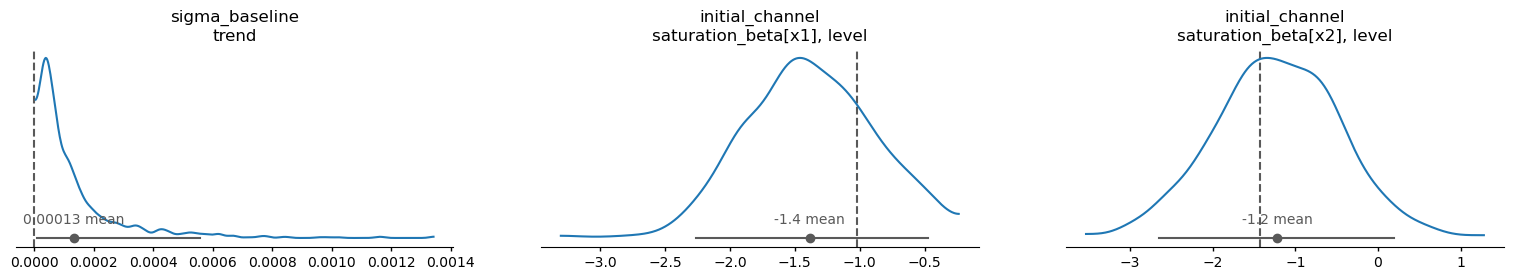

In [28]:
rich_point = {
    name: rich_estimate.posterior[name].isel(chain=0, draw=0, drop=True)
    for name in ["sigma_baseline", "initial_channel"]
}
true_rich_values = xr.Dataset(
    {
        "sigma_baseline": rich_point["sigma_baseline"].copy(data=[0.0]),
        "initial_channel": rich_point["initial_channel"].copy(
            data=np.log(channel_betas / sales_scale)[:, None]
        ),
    }
)
plot = az.plot_dist(rich_estimate, var_names=["sigma_baseline", "initial_channel"])
az.add_lines(plot, values=true_rich_values);

Sampling: [filtered_posterior, filtered_posterior_observed, predicted_posterior, predicted_posterior_observed, smoothed_posterior, smoothed_posterior_observed]


Output()

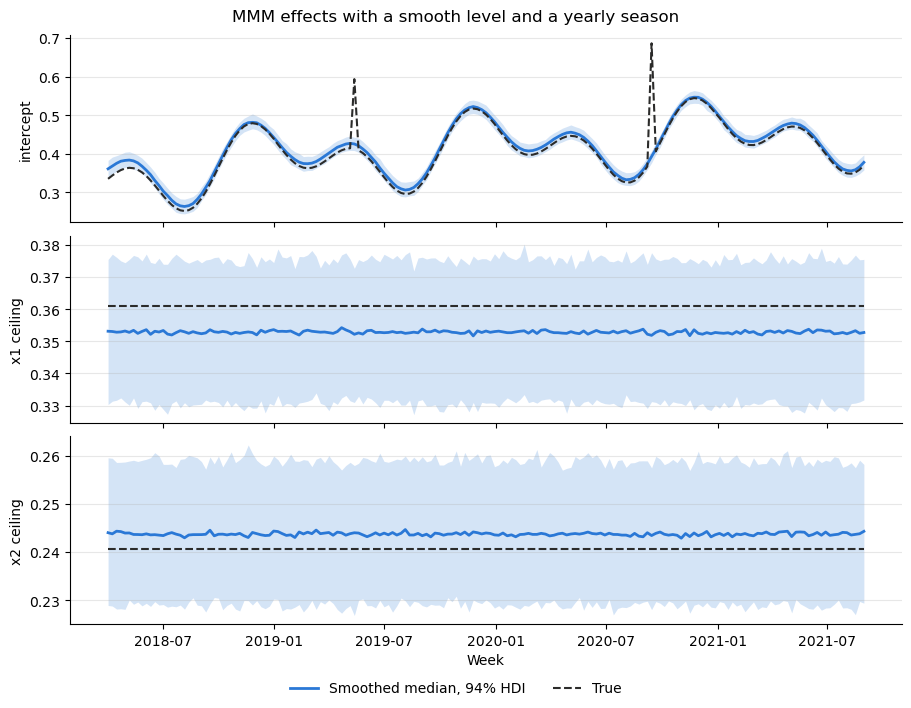

In [29]:
rich_conditional = rich_fused.sample_conditional_posterior(rich_estimate, random_seed=rng)

plot_paths(
    paths=effect_scale(rich_conditional["smoothed_posterior_observed"]),
    truth=true_paths_scaled,
    labels=mmm_labels,
    x=date_week,
    title="MMM effects with a smooth level and a yearly season",
);

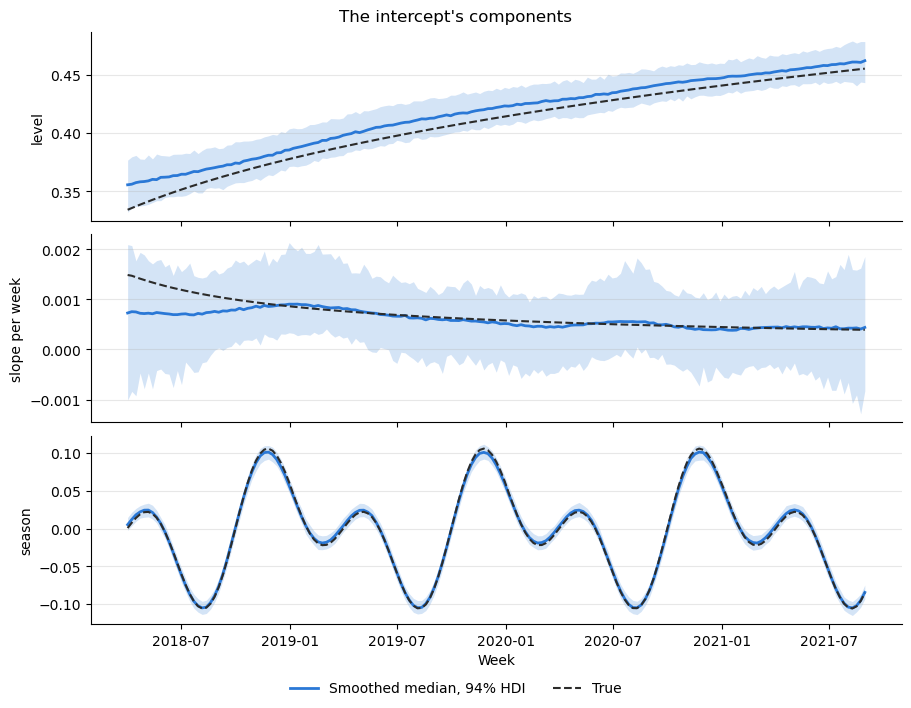

In [30]:
state_names = list(rich_fused.statespace.state_names)
level_index = state_names.index("level[intercept]")
slope_index = state_names.index("trend[intercept]")
season_indices = [index for index, name in enumerate(state_names) if "_season[" in name]

# The intercept's row of Z says how the Fourier states combine into the season.
posterior_mean = {
    name: rich_estimate.posterior[name].mean(("chain", "draw")).values
    for name in rich_fused.statespace.param_names
}
rich_design = rich_fused.statespace_matrices(
    statespace_parameters=posterior_mean, statespace_data={}
)[5].eval()

rich_states = rich_conditional["smoothed_posterior"]
components = xr.concat(
    [
        rich_states.isel(state=level_index, drop=True),
        rich_states.isel(state=slope_index, drop=True),
        (rich_states.isel(state=season_indices) * rich_design[0, season_indices]).sum("state"),
    ],
    dim="component",
)
component_hdi = az.hdi(components, prob=0.94)
component_median = components.median(("chain", "draw")).values

true_level = (2.0 + trend) / sales_scale
true_components = [true_level, np.gradient(true_level), seasonality / sales_scale]
labels = ["level", "slope per week", "season"]

fig, axes = plt.subplots(3, 1, figsize=(9, 7), sharex=True, layout="constrained")
for index, (axis, label) in enumerate(zip(axes, labels)):
    axis.fill_between(
        date_week,
        component_hdi.sel(ci_bound="lower").values[index],
        component_hdi.sel(ci_bound="upper").values[index],
        color=ESTIMATE_COLOR,
        alpha=0.2,
        linewidth=0,
    )
    axis.plot(
        date_week,
        component_median[index],
        color=ESTIMATE_COLOR,
        linewidth=2,
        label="Smoothed median, 94% HDI",
    )
    axis.plot(
        date_week,
        true_components[index],
        color=TRUTH_COLOR,
        linewidth=1.5,
        linestyle="--",
        label="True",
    )
    axis.set_ylabel(label)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="y", alpha=0.3)
axes[-1].set_xlabel("Week")
fig.suptitle("The intercept's components")
fig.legend(
    *axes[0].get_legend_handles_labels(), loc="outside lower center", ncols=2, frameon=False
);

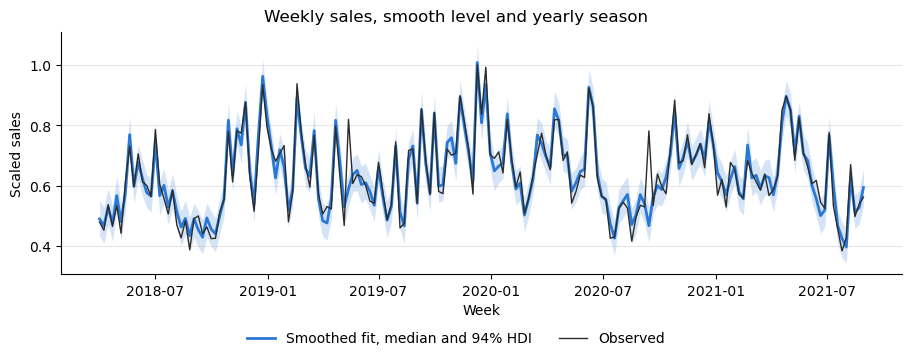

In [31]:
rich_fitted_sales = rich_fused.sample_conditional_observations(
    idata=rich_estimate, conditional=rich_conditional, kind="smoothed", random_seed=rng
)
plot_fitted_observations(
    draws=rich_fitted_sales["sales"],
    observed=sales_scaled,
    x=date_week,
    ylabel="Scaled sales",
    title="Weekly sales, smooth level and yearly season",
);